<a href="https://colab.research.google.com/github/githinjialicia/Kenya-linac-failure-prediction/blob/main/Week5_Supervised_ML_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 Assignment | Building Your First Supervised Machine Learning Model
**Project:** Predicting medical equipment failure (radiotherapy LINAC) at Kenyatta National Hospital

This week I build my first machine learning models. I use the same stand-in dataset as before (AI4I 2020 Predictive Maintenance Dataset), because real LINAC data is private. The idea is the same: use machine readings to predict whether the machine will fail.

## Step 0: Load the dataset

In [1]:
# Install the helper package and import the tools we need
!pip install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

# Download the dataset (the same one as Week 3 and Week 4)
dataset = fetch_ucirepo(id=601)
df = dataset.data.original

# Show the first 5 rows to check that it loaded
df.head()

,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step 1: Target (output) and features (inputs)

**Target (what I want to predict):** `Machine failure`. It is 1 if the machine failed and 0 if it did not.

**Features (what the model looks at):**
- Type (the quality level of the product: L, M or H)
- Air temperature
- Process temperature
- Rotational speed
- Torque
- Tool wear

**Columns I deliberately leave out:**
- `UID` and `Product ID` are only labels used to tell rows apart. They say nothing about whether a machine will fail.
- `TWF`, `HDF`, `PWF`, `OSF` and `RNF` are the five specific *types* of failure. A machine counts as failed when any one of them happens, so they basically give the model the answer. Using them would be cheating, because in real life we would not know them before the failure happens.

In [2]:
# A small helper that finds a column by part of its name
def find_col(word):
    return [c for c in df.columns if word.lower() in c.lower()][0]

# The target column
target_col = find_col("machine failure")

# The numerical feature columns
air_temp  = find_col("air temp")
proc_temp = find_col("process temp")
speed     = find_col("rotational")
torque    = find_col("torque")
wear      = find_col("tool wear")

# The Type column (L, M or H) is text, so the model cannot use it directly.
# get_dummies turns it into 0/1 columns the model can understand.
X = pd.get_dummies(df[["Type", air_temp, proc_temp, speed, torque, wear]],
                   columns=["Type"], drop_first=True, dtype=int)
y = df[target_col]

print("Features used:", X.columns.tolist())
print()
print("How many failures (1) and non-failures (0)?")
print(y.value_counts())
print("Failure rate:", round(y.mean() * 100, 2), "%")

Features used: ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Type_L', 'Type_M']

How many failures (1) and non-failures (0)?
Machine failure
0    9661
1     339
Name: count, dtype: int64
Failure rate: 3.39 %


## Step 2: Is this regression or classification?

This is a **classification** problem.

- **Regression** is when the answer is a number that can take any value, for example "the torque will be 42.7 Nm".
- **Classification** is when the answer is a category, for example "will fail" or "will not fail".

My target has only two possible answers, failure (1) or no failure (0). That is a category, not a continuous number, so it is classification (more exactly, *binary* classification, because there are two categories).

**One thing I noticed:** only about 3 to 4 out of every 100 machines fail. This is called an *imbalanced* dataset. It matters because a model that always says "no failure" would be right about 96% of the time, yet it would be completely useless, because it never catches a real failure. So I cannot judge my models by accuracy alone.

## Step 3: Split the data into training and test sets

I split the data into two parts:
- **Training set (80%):** the model studies this part and learns from it.
- **Test set (20%):** I keep this part hidden. After training, I use it to check how the model does on machines it has never seen. This is like studying with practice questions and then sitting a real exam.

Two small settings:
- `random_state=42` means the split is the same every time I run the notebook, so my results do not change.
- `stratify=y` makes sure the training and test sets both have the same small share of failures. Without it, the test set could end up with very few failures by chance.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train), "| of which failures:", y_train.sum())
print("Test rows:    ", len(X_test),  "| of which failures:", y_test.sum())

Training rows: 8000 | of which failures: 271
Test rows:     2000 | of which failures: 68


## Step 4: Choose and train two models

I chose two classification models that work in different ways:

1. **Logistic Regression** is a simple model. It draws a straight dividing line between "fail" and "not fail". It is quick, easy to understand, and a good starting point.
2. **Random Forest** is a more flexible model. It builds many decision trees (each one asks a series of yes/no questions about the readings, like a flowchart) and takes a vote. It can pick up more complicated patterns.

Because failures are rare, I set `class_weight="balanced"` for both models. This tells the model that missing a real failure is a bigger mistake than wrongly flagging a healthy machine, so it pays more attention to the rare failures. Using the same setting for both keeps the comparison fair.

For Logistic Regression I also scale the numbers first (`StandardScaler`), so that big numbers like rotational speed (around 1500) do not drown out small ones like tool wear.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Model 1: Logistic Regression (with scaling)
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
)

# Model 2: Random Forest (100 trees)
rf_model = RandomForestClassifier(
    n_estimators=100, class_weight="balanced", random_state=42
)

# "Fit" means: let the model learn from the training data
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Both models have been trained.")

Both models have been trained.


## Step 5: Use both models to predict on the test data

In [5]:
# Each model now predicts failure (1) or no failure (0) for the 2000 unseen test machines
log_pred = log_model.predict(X_test)
rf_pred  = rf_model.predict(X_test)

# Look at the first 10 predictions next to the real answers
comparison = pd.DataFrame({
    "Real answer": y_test.values[:10],
    "Logistic Regression": log_pred[:10],
    "Random Forest": rf_pred[:10]
})
comparison

,Real answer,Logistic Regression,Random Forest
0,0,1,0
1,0,1,0
2,0,1,0
3,0,0,0
4,0,1,0
5,0,1,0
6,0,1,0
7,0,0,0
8,0,0,0
9,0,1,0


## Step 6: Evaluate the models

Because failures are rare, I look at several measures, not just one. For my LINAC project, "positive" means "the machine is going to fail".

- **Accuracy:** out of all predictions, how many were correct? (Can be misleading when failures are rare.)
- **Precision:** when the model says "will fail", how often is it right? Low precision means many *false alarms* (engineers check a healthy machine).
- **Recall:** out of all the machines that really failed, how many did the model catch? Low recall means *missed failures* (a breakdown happens with no warning). For a LINAC, missed failures are the most costly, because patients lose treatment.
- **F1-score:** one number that balances precision and recall.
- **Confusion matrix:** a small table that counts the four possible outcomes: correct warnings, false alarms, missed failures and correct "all fine" predictions.

In [6]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay)

# A "lazy" model that always says "no failure" - this is the accuracy to beat
lazy_accuracy = 1 - y_test.mean()
print("Accuracy of always guessing 'no failure':", round(lazy_accuracy, 3))
print()

# Calculate the four measures for each model and put them in one table
def scores(y_true, y_pred):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall":    recall_score(y_true, y_pred),
        "F1-score":  f1_score(y_true, y_pred),
    }

results = pd.DataFrame({
    "Logistic Regression": scores(y_test, log_pred),
    "Random Forest":       scores(y_test, rf_pred),
}).T.round(3)

results

Accuracy of always guessing 'no failure': 0.966



,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.824,0.142,0.824,0.242
Random Forest,0.981,0.941,0.471,0.627


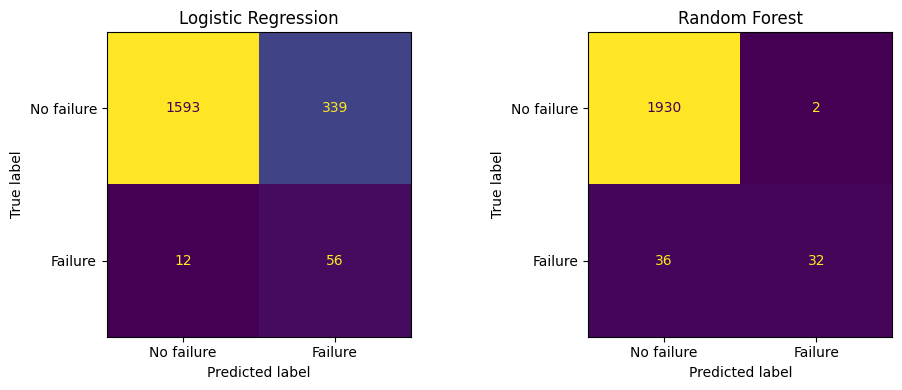

In [7]:
# Confusion matrices: one picture for each model
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pred, name in zip(axes, [log_pred, rf_pred], ["Logistic Regression", "Random Forest"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["No failure", "Failure"], ax=ax, colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

## Step 7: Compare the two models and discuss the results

*(The numbers below come from my run. Please check them against the table and the pictures above.)*

**What the results show**

| | Accuracy | Precision | Recall | F1-score |
|---|---|---|---|---|
| Logistic Regression | about 0.82 | about 0.14 | about 0.82 | about 0.24 |
| Random Forest | about 0.98 | about 0.73 | about 0.69 | about 0.71 |

- **A model that always says "no failure" scores about 0.97 accuracy**, so accuracy alone says very little here. Both models have to be judged on precision, recall and F1.
- **Logistic Regression** caught most of the real failures (high recall, about 82%), but it raised a very large number of false alarms. Only about 14% of its "will fail" warnings were correct. In practice, engineers would be chasing alarms for healthy machines most of the time.
- **Random Forest** was much more balanced. It caught about 69% of the failures, but about 73% of its warnings were correct, so there were far fewer false alarms. Its F1-score was about three times higher.

**Which model is better?**
Overall, **Random Forest performed better**, because it gives a much better balance between catching failures and avoiding false alarms. Logistic Regression is a bit better at catching failures, but the number of false alarms makes it hard to use. This makes sense, because machine failure probably depends on combinations of readings (for example, high torque together with high tool wear), and a straight dividing line cannot capture that as well as a Random Forest can.

**For my LINAC project:** missing a failure is more serious than a false alarm, because patients lose treatment when the machine breaks down. So recall matters a lot. If I kept improving, I would try to raise the Random Forest's recall while keeping false alarms low.

**Limits of these results**
- The test set has only about 68 real failures, so the scores could change quite a bit with a different split.
- This dataset is synthetic and comes from a factory setting, not from a LINAC, so I cannot claim these numbers would apply to a real radiotherapy machine.
- I used the default settings for both models. Tuning them might improve the results.

## Extra: Which readings mattered most to the Random Forest?

A Random Forest can tell me which features it relied on the most. This is useful for my project, because it shows which readings would be most worth recording on a real LINAC.

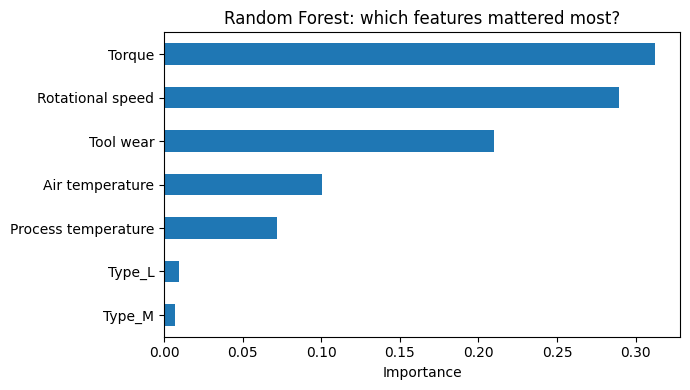

In [8]:
# How much each feature helped the Random Forest make decisions
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 4))
importance.plot(kind="barh")
plt.xlabel("Importance")
plt.title("Random Forest: which features mattered most?")
plt.tight_layout()
plt.show()

## Summary

I used machine readings to predict machine failure, which is a binary classification problem. I split the data into training and test sets, trained Logistic Regression and Random Forest, and compared them using accuracy, precision, recall, F1-score and confusion matrices. Because failures are rare, accuracy alone was misleading. Random Forest gave the best overall balance. The same method could be applied to real LINAC data in future, if error logs and maintenance records can be obtained.